# Train B1 — YOLOv8s-P2 (100 epochs, imgsz=1024, stride-4 detection head, no early-stop) — Kaggle GPU
**KLTN: Hệ Thống Nhận Diện & Đánh Giá Khuyết Tật Bo Mạch In (PCB Defect Detection)**

---

### 📌 Mục tiêu thí nghiệm B1 (YOLOv8s-P2):
1. **Kiến trúc cải tiến**: Giữ nguyên dòng model **YOLOv8s** (100 epochs, cùng dataset PKU, cùng split group-aware), nhưng bổ sung một detection head **P2 (stride 4, feature map 256×256 tại imgsz=1024)** để tăng cường khả năng phát hiện khuyết tật vi mô.
2. **Khởi tạo & Weight Transfer**:
   - Định nghĩa kiến trúc tại `configs/yolov8s-p2.yaml` (dựa trên YAML chính thức của Ultralytics, scale `s`, `nc=6`).
   - Khởi tạo kiến trúc mới và chuyển giao trọng số tương thích (219/437 items) từ pretrained `yolov8s.pt` (backbone & neck tương thích), detection head P2 mới được khởi tạo ngẫu nhiên.
3. **Giả thuyết khoa học khóa trước**:
   *P2 tăng Recall của các khuyết tật kích thước nhỏ (đặc biệt `Mouse_bite` và `Spur`) so với baseline B0 toàn ảnh, đổi lại chi phí tính toán (37.0 GFLOPs vs 28.6 GFLOPs) và VRAM tăng lên; không mặc định rằng mAP tổng thể sẽ tự động tăng.*
4. **Tính công bằng & Chống rò rỉ (Fairness & No Data Leakage)**:
   - Dùng cùng `train.txt` (2,416 ảnh) và `val.txt` (608 ảnh); `test.txt` (480 ảnh) KHÔNG đưa vào training.
   - Giữ nguyên công thức tối ưu: AdamW, Cosine LR, `close_mosaic=15`, cùng augmentation bo mạch (không xoay nghiêng méo góc).
   - **Ghi chú về Batch Size**: Do head P2 có 87,040 anchor points (gấp 4 lần B0: 21,760), batch 16 sẽ tiêu tốn ~17GB VRAM dẫn đến CUDA OOM trên GPU T4 (15GB). Do đó B1 sử dụng **batch=8**, Ultralytics tự động kích hoạt gradient accumulation (`nbs=64`) để bảo toàn động lượng gradient step.

---

### 🗺️ Lộ trình thực hiện:
- **Cell 1:** Cài `ultralytics==8.3.40`, gỡ `ray` conflict trên Kaggle.
- **Cell 2:** Import thư viện; giải nén bundle `pcb_b1_yolov8s_p2_project_data.zip`; kiểm tra GPU & dataset PKU.
- **Cell 3:** Nạp hyperparams & kiến trúc `yolov8s-p2.yaml`; thiết lập cấu hình B1.
- **Cell 4:** Remap split files; kiểm tra nhãn & thống kê GT boxes.
- **Cell 5:** Ghi split files vào working dir; tạo `data_kaggle_train_val.yaml`.
- **Cell 6:** **Sanity Check**: Kiểm tra model info (160 layers, 10.64M params, 37.0 GFLOPs, 4 detection scales) & dummy forward pass.
- **Cell 7:** Fix Ray Tune incompatibility trước khi gọi `model.train()`.
- **Cell 8:** **Huấn luyện B1_yolov8s_p2_100ep** (100 epochs, AdamW, Cosine LR).
- **Cell 9:** Validation tổng quan và bảng kết quả theo lớp (mAP50, mAP50-95, Precision, Recall).
- **Cell 10:** Phân tích False Negative (FN) theo Size Bin (small, medium, large) & theo Class.
- **Cell 11:** **So sánh đối đầu B0 (YOLOv8s baseline) vs B1 (YOLOv8s-P2)** trên Validation.
- **Cell 12:** Ghi metadata run (GPU, GFLOPs, hyperparams, metrics).
- **Cell 13:** Đóng gói ZIP kết quả `B1_yolov8s_p2_results.zip` & link tải trực tiếp.
- **Cell 14:** Kết luận & phân tích khoa học cho báo cáo KLTN.


---
## Cell 1 — Cài / upgrade ultralytics; gỡ ray để tránh conflict trên Kaggle.


In [1]:
!pip uninstall ray -y -q 2>/dev/null || True
!pip install ultralytics==8.3.40 -q --upgrade
print("✅ ultralytics installed, ray removed")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 898.5/898.5 kB 7.7 MB/s eta 0:00:0000:0100:01
✅ ultralytics installed, ray removed


---
## Cell 2 — Import thư viện; giải nén project bundle; kiểm tra GPU & dataset PKU.


In [2]:
import json, hashlib, shutil, subprocess, sys, time, zipfile
from contextlib import redirect_stdout, redirect_stderr
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from IPython.display import display, FileLink
from ultralytics import YOLO

# ── Kaggle dataset paths ──────────────────────────────────────────────────────
KAGGLE_IMG_ROOT_PREFERRED = Path(
    "/kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)"
)

WORK_DIR        = Path("/kaggle/working")
ZIP_NAME        = "pcb_b1_yolov8s_p2_project_data.zip"
BUNDLE_DIR_NAME = "pcb_b1_yolov8s_p2_project_data"
BUNDLE_ROOT     = WORK_DIR / BUNDLE_DIR_NAME

# ── Tìm và giải nén project bundle ────────────────────────────────────────────
input_root     = Path("/kaggle/input")
zip_candidates = list(input_root.rglob(ZIP_NAME))

# Hỗ trợ tìm cả bundle B0 nếu user upload bundle cũ
if not zip_candidates:
    zip_candidates = list(input_root.rglob("pcb_b0_yolov8s_batch16_project_data.zip"))

if len(zip_candidates) >= 1:
    BUNDLE_ZIP = zip_candidates[0]
    with zipfile.ZipFile(BUNDLE_ZIP) as zf:
        bad = zf.testzip()
        assert bad is None, f"ZIP lỗi: {bad}"
        zf.extractall(WORK_DIR)
    print(f"✅ Giải nén bundle: {BUNDLE_ZIP}")
    # Xác định thư mục đã giải nén
    extracted_dirs = [d for d in WORK_DIR.iterdir() if d.is_dir() and "project_data" in d.name]
    if extracted_dirs:
        BUNDLE_ROOT = extracted_dirs[0]
else:
    # Kaggle mount thư mục đã giải nén
    bundle_candidates = []
    for cfg_path in input_root.rglob("base.yaml"):
        if cfg_path.parent.name != "configs":
            continue
        root = cfg_path.parent.parent
        if ((root/"data/splits/train.txt").is_file() and (root/"data/splits/val.txt").is_file()
                and (root/"split_info.json").is_file()):
            bundle_candidates.append(root)

    if len(bundle_candidates) > 1:
        matched = [b for b in bundle_candidates if "yolov8" in str(b).lower() or "p2" in str(b).lower()]
        if len(matched) >= 1:
            bundle_candidates = matched

    assert len(bundle_candidates) >= 1, (
        f"Không tìm thấy project bundle trên Kaggle input; zip={len(zip_candidates)}, folders={bundle_candidates[:5]}"
    )
    BUNDLE_ROOT = bundle_candidates[0]
    print(f"✅ Dùng bundle đã giải nén: {BUNDLE_ROOT}")

# ── Verify checksum split files ───────────────────────────────────────────────
split_info = json.loads((BUNDLE_ROOT/"split_info.json").read_text())
for split in ("train", "val"):
    split_bytes = (BUNDLE_ROOT/"data/splits"/f"{split}.txt").read_bytes()
    assert hashlib.md5(split_bytes).hexdigest() == split_info[f"{split}_txt_md5"], f"Checksum split {split} không khớp"
print("✅ Checksums split files OK (train=2416, val=608)")

# ── Tìm dataset PKU ───────────────────────────────────────────────────────────
if KAGGLE_IMG_ROOT_PREFERRED.is_dir():
    KAGGLE_IMG_ROOT = KAGGLE_IMG_ROOT_PREFERRED
else:
    candidates = [p for p in Path("/kaggle/input").rglob("PKU-Market-PCB(Data enhanced version)")
                  if (p/"train/images").is_dir() and (p/"train/labels").is_dir()]
    assert len(candidates) >= 1, f"Không xác định duy nhất được thư mục PKU: {candidates[:5]}"
    KAGGLE_IMG_ROOT = candidates[0]

print("✅ Dataset ảnh:", KAGGLE_IMG_ROOT)
print(f"   Train images: {len(list((KAGGLE_IMG_ROOT/'train'/'images').glob('*.jpg')))}")
print(f"   Valid images: {len(list((KAGGLE_IMG_ROOT/'valid'/'images').glob('*.jpg')))}")
print(f"   Test images : {len(list((KAGGLE_IMG_ROOT/'test' /'images').glob('*.jpg')))}")
print()
print("✅ GPU:", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
assert torch.cuda.is_available(), "Hãy bật GPU trong Kaggle Notebook Settings (GPU T4 x2 hoặc T4)."


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
✅ Dùng bundle đã giải nén: /kaggle/input/datasets/tanthongthai/pcb-b1-yolov8s-p2-project-data/pcb_b1_yolov8s_p2_project_data
✅ Checksums split files OK (train=2416, val=608)
✅ Dataset ảnh: /kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)
   Train images: 2772
   Valid images: 366
   Test images : 366

✅ GPU: ['Tesla T4', 'Tesla T4']


---
## Cell 3 — Load hyperparams từ configs/base.yaml; thiết lập kiến trúc YOLOv8s-P2.


In [3]:
cfg = yaml.safe_load((BUNDLE_ROOT / "configs" / "base.yaml").read_text())
print("✅ Loaded configs/base.yaml:", cfg)

CLASSES = ["Missing_hole", "Mouse_bite", "Open_circuit", "Short", "Spur", "Spurious_copper"]

# ===== CẤU HÌNH KIẾN TRÚC YOLOv8s-P2 (nc=6) =====
# Nhúng sẵn YAML để notebook có thể chạy hoàn toàn độc lập ngay cả khi không có file ngoài.
YOLOV8S_P2_YAML_CONTENT = """# YOLOv8s-P2 — PCB Micro Defect Detection (PKU-Market-PCB, 6 classes)
nc: 6

scales:
  # [depth, width, max_channels]
  s: [0.33, 0.50, 1024]

# YOLOv8 backbone
backbone:
  # [from, repeats, module, args]
  - [-1, 1, Conv,    [64, 3, 2]]          # 0-P1/2
  - [-1, 1, Conv,    [128, 3, 2]]         # 1-P2/4   <- P2 feature
  - [-1, 3, C2f,     [128, True]]         # 2-P2/4
  - [-1, 1, Conv,    [256, 3, 2]]         # 3-P3/8
  - [-1, 6, C2f,     [256, True]]         # 4-P3/8
  - [-1, 1, Conv,    [512, 3, 2]]         # 5-P4/16
  - [-1, 6, C2f,     [512, True]]         # 6-P4/16
  - [-1, 1, Conv,    [1024, 3, 2]]        # 7-P5/32
  - [-1, 3, C2f,     [1024, True]]        # 8-P5/32
  - [-1, 1, SPPF,    [1024, 5]]           # 9-P5/32

# YOLOv8-P2 head (4 detection outputs: stride 4, 8, 16, 32)
head:
  - [-1,  1, nn.Upsample, [None, 2, "nearest"]]  # 10: P5 -> P4
  - [[-1, 6], 1, Concat,  [1]]                   # 11: cat backbone P4
  - [-1,  3, C2f,  [512, False]]                  # 12: P4 fused

  - [-1,  1, nn.Upsample, [None, 2, "nearest"]]  # 13: P4 -> P3
  - [[-1, 4], 1, Concat,  [1]]                   # 14: cat backbone P3
  - [-1,  3, C2f,  [256, False]]                  # 15: P3 fused (stride 8)

  - [-1,  1, nn.Upsample, [None, 2, "nearest"]]  # 16: P3 -> P2
  - [[-1, 2], 1, Concat,  [1]]                   # 17: cat backbone P2
  - [-1,  3, C2f,  [128, False]]                  # 18: P2 fused (stride 4)  <- Detection Head 1

  - [-1,  1, Conv,  [128, 3, 2]]                  # 19: P2 -> P3
  - [[-1, 15], 1, Concat, [1]]                    # 20: cat P3
  - [-1,  3, C2f,  [256, False]]                  # 21: P3 fused             <- Detection Head 2 (stride 8)

  - [-1,  1, Conv,  [256, 3, 2]]                  # 22: P3 -> P4
  - [[-1, 12], 1, Concat, [1]]                    # 23: cat P4
  - [-1,  3, C2f,  [512, False]]                  # 24: P4 fused             <- Detection Head 3 (stride 16)

  - [-1,  1, Conv,  [512, 3, 2]]                  # 25: P4 -> P5
  - [[-1,  9], 1, Concat, [1]]                    # 26: cat P5
  - [-1,  3, C2f,  [1024, False]]                 # 27: P5 fused             <- Detection Head 4 (stride 32)

  - [[18, 21, 24, 27], 1, Detect, [nc]]           # 28: Detect(P2, P3, P4, P5)
"""

WORK_DIR.mkdir(parents=True, exist_ok=True)
MODEL_YAML = WORK_DIR / "yolov8s-p2.yaml"

if (BUNDLE_ROOT / "configs" / "yolov8s-p2.yaml").is_file():
    shutil.copy(BUNDLE_ROOT / "configs" / "yolov8s-p2.yaml", MODEL_YAML)
    print(f"✅ Dùng configs/yolov8s-p2.yaml từ bundle: {MODEL_YAML}")
else:
    MODEL_YAML.write_text(YOLOV8S_P2_YAML_CONTENT, encoding="utf-8")
    print(f"✅ Đã tạo yolov8s-p2.yaml nhúng sẵn tại {MODEL_YAML}")

# ===== HYPERPARAMETERS B1 YOLOv8s-P2 =====
BASE_WEIGHTS = "yolov8s.pt"             # Pretrained checkpoint để nạp weights tương thích
EPOCHS       = int(cfg["epochs"])       # 100 epochs
PATIENCE     = int(cfg["patience"])     # = EPOCHS -> KHÔNG dừng sớm
IMGSZ        = int(cfg["imgsz"])        # 1024x1024 (P2 feature map: 256x256)
SEED         = int(cfg["seed"])         # 42
OPTIMIZER    = str(cfg["optimizer"])    # AdamW
AUG          = cfg["augmentation"]
RUN_NAME     = "B1_yolov8s_p2_100ep"
RUNS_DIR     = WORK_DIR / "runs"

# ── Cấu hình BATCH = 8 và DEVICE = 0 (Tránh CUDA OOM trên T4 15GB) ───────────
# B1 có thêm head P2 (256x256, 87,040 anchor points, gấp 4 lần B0: 21,760).
# Trên GPU T4 (15GB), batch=16 sẽ tiêu thụ ~17GB VRAM dẫn đến OOM.
# Đặt BATCH = 8 tiêu thụ an toàn ~9.0GB VRAM.
# Ultralytics tự động tích lũy gradient (nbs=64) để tương đương gradient step của batch 16.
DEVICE = 0
BATCH  = 8
# ==========================================

print(f"\nHyperparams cho {RUN_NAME}:")
print(f"  arch yaml : {MODEL_YAML} (YOLOv8s + P2 stride-4 head)")
print(f"  base wts  : {BASE_WEIGHTS} (COCO pretrained transfer)")
print(f"  imgsz     : {IMGSZ} (P2->256x256, P3->128x128, P4->64x64, P5->32x32)")
print(f"  epochs    : {EPOCHS} (100 epochs, không early-stop)")
print(f"  patience  : {PATIENCE}")
print(f"  batch     : {BATCH} (an toàn VRAM ~9GB/15GB, gradient accumulation x2)")
print(f"  device    : {DEVICE}")
print(f"  seed      : {SEED}")
print(f"  optimizer : {OPTIMIZER}")


✅ Loaded configs/base.yaml: {'experiment_name': 'B0_yolo11', 'model': 'yolo11s.pt', 'data': 'data/data.yaml', 'imgsz': 1024, 'epochs': 100, 'batch': 16, 'seed': 42, 'patience': 100, 'optimizer': 'AdamW', 'device': 0, 'augmentation': {'degrees': 0.0, 'shear': 0.0, 'perspective': 0.0, 'flipud': 0.5, 'fliplr': 0.5, 'mosaic': 0.8, 'close_mosaic': 15, 'hsv_h': 0.015, 'hsv_s': 0.7, 'hsv_v': 0.4}, 'predict_conf': 0.25, 'predict_iou': 0.7}
✅ Dùng configs/yolov8s-p2.yaml từ bundle: /kaggle/working/yolov8s-p2.yaml

Hyperparams cho B1_yolov8s_p2_100ep:
  arch yaml : /kaggle/working/yolov8s-p2.yaml (YOLOv8s + P2 stride-4 head)
  base wts  : yolov8s.pt (COCO pretrained transfer)
  imgsz     : 1024 (P2->256x256, P3->128x128, P4->64x64, P5->32x32)
  epochs    : 100 (100 epochs, không early-stop)
  patience  : 100
  batch     : 8 (an toàn VRAM ~9GB/15GB, gradient accumulation x2)
  device    : 0
  seed      : 42
  optimizer : AdamW


---
## Cell 4 — Load split files; remap đường dẫn local → Kaggle absolute path; kiểm tra nhãn.


In [4]:
LOCAL_PREFIX = "data/raw/PKU-Market-PCB(Data enhanced version)/"

def remap_split(name: str) -> list:
    """
    Đọc split .txt, remap sang Kaggle absolute path.
    Kiểm tra ảnh và nhãn tồn tại; đảm bảo class_id hợp lệ.
    """
    src = BUNDLE_ROOT / "data" / "splits" / f"{name}.txt"
    assert src.is_file(), f"Thiếu split list: {src}"
    output = []
    for line in src.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if not line:
            continue
        assert line.startswith(LOCAL_PREFIX), f"Đường dẫn ngoài dataset PKU: {line}"
        rel = line[len(LOCAL_PREFIX):]
        img = KAGGLE_IMG_ROOT / rel
        assert img.is_file(), f"Không thấy ảnh theo split {name}: {img}"
        label = img.parent.parent / "labels" / f"{img.stem}.txt"
        assert label.is_file(), f"Không thấy nhãn gốc của ảnh: {label}"
        output.append(str(img))
    return output

train_paths = remap_split("train")
val_paths   = remap_split("val")

assert len(train_paths) == 2416 and len(val_paths) == 608, (
    f"Số ảnh không khớp: train={len(train_paths)}, val={len(val_paths)}"
)
assert len(set(train_paths)) == len(train_paths) and len(set(val_paths)) == len(val_paths), \
    "Có ảnh trùng lặp trong split"

print(f"✅ Loaded splits: train={len(train_paths)}, val={len(val_paths)}")

# ── Kiểm tra class_id và thống kê GT ─────────────────────────────────────────
class_counts = {i: 0 for i in range(6)}
for image_path in train_paths + val_paths:
    image = Path(image_path)
    label = image.parent.parent / "labels" / f"{image.stem}.txt"
    for row in label.read_text(encoding="utf-8").splitlines():
        if row.strip():
            cid = int(row.split()[0])
            assert 0 <= cid < 6, f"class_id không hợp lệ: {label}: {cid}"
            class_counts[cid] += 1
assert all(v > 0 for v in class_counts.values()), f"Có lớp không có box: {class_counts}"
print("\n✅ Thống kê GT boxes (train + val):")
display(pd.DataFrame([{"class_id": i, "class": CLASSES[i], "GT boxes train+val": class_counts[i]} for i in range(6)]))


✅ Loaded splits: train=2416, val=608

✅ Thống kê GT boxes (train + val):


,class_id,class,GT boxes train+val
0,0,Missing_hole,2026
1,1,Mouse_bite,2010
2,2,Open_circuit,1934
3,3,Short,1992
4,4,Spur,1982
5,5,Spurious_copper,2058


---
## Cell 5 — Ghi split files vào working dir; tạo data_kaggle_train_val.yaml cho training.


In [5]:
WORK_DIR.mkdir(parents=True, exist_ok=True)
splits_dir = WORK_DIR / "splits"
splits_dir.mkdir(exist_ok=True)

train_txt_kaggle = splits_dir / "train.txt"
val_txt_kaggle   = splits_dir / "val.txt"

train_txt_kaggle.write_text("\n".join(train_paths) + "\n", encoding="utf-8")
val_txt_kaggle.write_text(  "\n".join(val_paths)   + "\n", encoding="utf-8")

print(f"✅ Wrote train.txt: {len(train_paths)} images")
print(f"✅ Wrote val.txt  : {len(val_paths)} images")

# ── Tạo data.yaml chỉ có train/val (test KHÔNG được thêm để tránh data leakage) ─
DATA_YAML = WORK_DIR / "data_kaggle_train_val.yaml"
data_cfg  = {
    "path"  : str(KAGGLE_IMG_ROOT),
    "train" : str(train_txt_kaggle),
    "val"   : str(val_txt_kaggle),
    "nc"    : 6,
    "names" : {i: name for i, name in enumerate(CLASSES)},
}
DATA_YAML.write_text(
    yaml.safe_dump(data_cfg, sort_keys=False, allow_unicode=True),
    encoding="utf-8"
)

print(f"\n✅ data_kaggle_train_val.yaml:")
print(DATA_YAML.read_text())


✅ Wrote train.txt: 2416 images
✅ Wrote val.txt  : 608 images

✅ data_kaggle_train_val.yaml:
path: /kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data
  enhanced version)
train: /kaggle/working/splits/train.txt
val: /kaggle/working/splits/val.txt
nc: 6
names:
  0: Missing_hole
  1: Mouse_bite
  2: Open_circuit
  3: Short
  4: Spur
  5: Spurious_copper



---
## Cell 6 — Sanity Check: Kiểm tra kiến trúc YOLOv8s-P2 trước khi train dài.

Trước khi huấn luyện 100 epochs, ta xác nhận:
1. `YOLO(MODEL_YAML).load(BASE_WEIGHTS)` khởi tạo thành công và chuyển giao trọng số tương thích.
2. `nc = 6`, `len(model.names) == 6`.
3. `model.info()` trả về thông số kiến trúc hợp lệ (~10.64M params, ~37.0 GFLOPs).
4. Forward pass với tensor ảo `(1, 3, 1024, 1024)` cho đủ **4 detection scales** (stride 4, 8, 16, 32) với tổng cộng **87,040 anchor points** mà không có lỗi shape.


In [6]:
print("🔍 Bắt đầu Sanity Check kiến trúc YOLOv8s-P2...")

# 1. Khởi tạo model và load pretrained weights
test_model = YOLO(str(MODEL_YAML))
test_model.load(BASE_WEIGHTS)
print("✅ Khởi tạo và load pretrained weights thành công!")

# 2. Kiểm tra số class
assert test_model.model.yaml.get("nc") == 6, f"nc không đúng: {test_model.model.yaml.get('nc')}"
print("✅ nc = 6 chính xác.")

# 3. Model info & GFLOPs
info = test_model.info()
layers, params, grads, gflops = info
print(f"\n📊 Thông số YOLOv8s-P2:")
print(f"   Layers : {layers}")
print(f"   Params : {params:,} (~{params/1e6:.2f}M)")
print(f"   GFLOPs : {gflops:.1f} GFLOPs (tại 1024x1024)")
assert gflops > 0, "GFLOPs phải khác 0"

# 4. Forward pass kiểm tra 4 detection scales
test_model.model.eval()
with torch.no_grad():
    dummy_x = torch.zeros(1, 3, IMGSZ, IMGSZ)
    dummy_out = test_model.model(dummy_x)

assert isinstance(dummy_out, tuple) and len(dummy_out) >= 1, "Output forward pass không đúng định dạng tuple"
preds_tensor = dummy_out[0]
print(f"\n✅ Forward pass dummy tensor (1, 3, {IMGSZ}, {IMGSZ}):")
print(f"   Preds shape: {preds_tensor.shape}")

# Kiểm tra shape: [batch=1, channels=(4 bbox + 6 classes)=10, total_anchors=87040]
# Stride 4: 256*256 = 65,536
# Stride 8: 128*128 = 16,384
# Stride 16: 64*64  =  4,096
# Stride 32: 32*32  =  1,024
# Total: 65,536 + 16,384 + 4,096 + 1,024 = 87,040 anchors
expected_anchors = 87040
assert preds_tensor.shape == (1, 10, expected_anchors), (
    f"Preds shape không khớp kỳ vọng: nhận {preds_tensor.shape}, mong muốn (1, 10, {expected_anchors})"
)
print(f"   Đúng 87,040 anchor points (gấp 4 lần B0: 21,760) từ 4 detection scales:")
print(f"     • P2 (stride  4): 256×256 = 65,536 anchors  <- Lỗi vi mô (Mouse_bite, Spur)")
print(f"     • P3 (stride  8): 128×128 = 16,384 anchors")
print(f"     • P4 (stride 16):  64×64  =  4,096 anchors")
print(f"     • P5 (stride 32):  32×32  =  1,024 anchors")

del test_model, dummy_x, dummy_out
torch.cuda.empty_cache() if torch.cuda.is_available() else None
print("\n🎉 SANITY CHECK HOÀN TẤT: Kiến trúc YOLOv8s-P2 hợp lệ 100%, sẵn sàng train dài!")


🔍 Bắt đầu Sanity Check kiến trúc YOLOv8s-P2...


100%|██████████| 21.5M/21.5M [00:00<00:00, 79.0MB/s]


Transferred 219/437 items from pretrained weights
✅ Khởi tạo và load pretrained weights thành công!
✅ nc = 6 chính xác.
YOLOv8s-p2 summary: 277 layers, 10,638,536 parameters, 10,638,520 gradients, 37.0 GFLOPs

📊 Thông số YOLOv8s-P2:
   Layers : 277
   Params : 10,638,536 (~10.64M)
   GFLOPs : 37.0 GFLOPs (tại 1024x1024)

✅ Forward pass dummy tensor (1, 3, 1024, 1024):
   Preds shape: torch.Size([1, 10, 87040])
   Đúng 87,040 anchor points (gấp 4 lần B0: 21,760) từ 4 detection scales:
     • P2 (stride  4): 256×256 = 65,536 anchors  <- Lỗi vi mô (Mouse_bite, Spur)
     • P3 (stride  8): 128×128 = 16,384 anchors
     • P4 (stride 16):  64×64  =  4,096 anchors
     • P5 (stride 32):  32×32  =  1,024 anchors

🎉 SANITY CHECK HOÀN TẤT: Kiến trúc YOLOv8s-P2 hợp lệ 100%, sẵn sàng train dài!


---
## Cell 7 — Fix Ray Tune incompatibility — PHẢI chạy trước model.train().


In [7]:
import ultralytics.utils.callbacks.raytune as _raytune_cb
_raytune_cb.callbacks.clear()
print("✅ Cleared raytune callbacks")


✅ Cleared raytune callbacks


---
## Cell 8 — Train B1_yolov8s_p2_100ep — YOLOv8s+P2 (1024x1024, batch=8, Cosine LR, Close Mosaic 15 ep).


In [8]:
RUN_DIR  = RUNS_DIR / RUN_NAME
last_pt  = RUN_DIR / "weights" / "last.pt"

# Bật FORCE_FRESH_START = True để train mới hoàn toàn với YOLOv8s-P2 (1024x1024)
FORCE_FRESH_START = True
RESUME = (not FORCE_FRESH_START) and last_pt.is_file()

assert not RUN_DIR.exists() or FORCE_FRESH_START, (
    f"Không ghi đè run đã tồn tại: {RUN_DIR}; đổi RUN_NAME nếu chủ động tạo run khác."
)

if RESUME:
    print(f"⚠️  Tìm thấy last.pt -> Resume từ checkpoint: {last_pt}")
    model = YOLO(str(last_pt))
else:
    if FORCE_FRESH_START and RUN_DIR.exists():
        print(f"🧹 Làm sạch runs cũ để train mới hoàn toàn với YOLOv8s-P2 (imgsz={IMGSZ}) ...")
        shutil.rmtree(RUN_DIR, ignore_errors=True)
    print(f"Khởi tạo B1 từ kiến trúc {MODEL_YAML} + pretrained weights {BASE_WEIGHTS} ...")
    model = YOLO(str(MODEL_YAML)).load(BASE_WEIGHTS)

# Loại bỏ raytune callback khỏi instance model
model.callbacks['on_fit_epoch_end'] = [
    cb for cb in model.callbacks['on_fit_epoch_end']
    if not cb.__module__.endswith('.raytune')
]
print("✅ Tiếp tục từ last.pt" if RESUME else f"✅ Khởi tạo {RUN_NAME} từ {BASE_WEIGHTS}")

t0         = time.time()
trained_at = datetime.now(timezone.utc).isoformat()

print(f"\n=== BẮT ĐẦU HUẤN LUYỆN B1 (YOLOv8s+P2, {EPOCHS} EPOCHS, IMGSZ={IMGSZ}, BATCH={BATCH}) ===")

# ── Ghi log song song vào training.log ───────────────────────────────────────
class Tee:
    def __init__(self, *streams): self.streams = streams
    def write(self, text):
        for stream in self.streams:
            stream.write(text); stream.flush()
        return len(text)
    def flush(self):
        for stream in self.streams: stream.flush()

log_path = WORK_DIR / "training.log"
with log_path.open("w", encoding="utf-8") as log_file:
    stdout0, stderr0 = sys.stdout, sys.stderr
    with redirect_stdout(Tee(stdout0, log_file)), redirect_stderr(Tee(stderr0, log_file)):
        results = model.train(
            data          = str(DATA_YAML),
            epochs        = EPOCHS,
            batch         = BATCH,
            imgsz         = IMGSZ,
            seed          = SEED,
            patience      = PATIENCE,    # 100 -> không dừng sớm
            optimizer     = OPTIMIZER,   # AdamW
            lr0           = 0.001,
            lrf           = 0.01,
            cos_lr        = True,        # Cosine Learning Rate Schedule
            project       = str(RUNS_DIR),
            name          = RUN_NAME,
            device        = 0,
            verbose       = True,
            save          = True,
            plots         = True,
            exist_ok      = True,
            workers       = 2,
            deterministic = True,
            val           = True,
            resume        = str(last_pt) if RESUME else False,
            close_mosaic  = 15,          # Tắt Mosaic ở 15 epoch cuối để hội tụ sắc nét
            # ── Augmentation tối ưu cho bo mạch PCB (Giữ nguyên chuẩn B0) ───
            degrees       = float(AUG["degrees"]),    # Không xoay nghiêng méo góc
            shear         = float(AUG["shear"]),
            perspective   = float(AUG["perspective"]),
            flipud        = float(AUG["flipud"]),     # Bật lật dọc cho bo mạch
            fliplr        = float(AUG["fliplr"]),     # Lật ngang
            mosaic        = float(AUG["mosaic"]),     # Giảm nhẹ mosaic
            mixup         = 0.0,
            copy_paste    = 0.0,
            hsv_h         = float(AUG["hsv_h"]),
            hsv_s         = float(AUG["hsv_s"]),
            hsv_v         = float(AUG["hsv_v"]),
            scale         = 0.5,
            translate     = 0.1,
        )

elapsed = time.time() - t0

best_pt = RUN_DIR / "weights" / "best.pt"
if not best_pt.is_file():
    raise FileNotFoundError("Train chưa hoàn tất: không có best.pt")

print(f"\n{'='*60}")
print(f"Training hoàn tất! Elapsed: {elapsed/60:.1f} phút")
print(f"{'='*60}")

m = results.results_dict
print(f"mAP50    : {m.get('metrics/mAP50(B)',    0):.4f}")
print(f"mAP50-95 : {m.get('metrics/mAP50-95(B)',0):.4f}")
print(f"Precision: {m.get('metrics/precision(B)',0):.4f}")
print(f"Recall   : {m.get('metrics/recall(B)',   0):.4f}")


Khởi tạo B1 từ kiến trúc /kaggle/working/yolov8s-p2.yaml + pretrained weights yolov8s.pt ...
Transferred 219/437 items from pretrained weights
✅ Khởi tạo B1_yolov8s_p2_100ep từ yolov8s.pt

=== BẮT ĐẦU HUẤN LUYỆN B1 (YOLOv8s+P2, 100 EPOCHS, IMGSZ=1024, BATCH=8) ===
New https://pypi.org/project/ultralytics/8.4.183 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.40 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: task=detect, mode=train, model=/kaggle/working/yolov8s-p2.yaml, data=/kaggle/working/data_kaggle_train_val.yaml, epochs=100, time=None, patience=100, batch=8, imgsz=1024, save=True, save_period=-1, cache=False, device=0, workers=2, project=/kaggle/working/runs, name=B1_yolov8s_p2_100ep, exist_ok=True, pretrained=yolov8s.pt, optimizer=AdamW, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=True, close_mosaic=15, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, ove

100%|##########| 755k/755k [00:00<00:00, 17.9MB/s]
E0000 00:00:1792636423.318457      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792636423.374993      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792636423.932239      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792636423.932265      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792636423.932267      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792636423.932270      57 computation_placer.cc:177] comput


                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     29056  ultralytics.nn.modules.block.C2f             [64, 64, 1, True]             
  3                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  4                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  5                  -1  1    295424  ultralytics.nn.modules.conv.Conv             [128, 256, 3, 2]              
  6                  -1  2    788480  ultralytics.nn.modules.block.C2f             [256, 256, 2, True]           
  7                  -1  1   1180672  ultralytics.nn.modules.conv.Conv             [256

100%|##########| 5.35M/5.35M [00:00<00:00, 65.9MB/s]


AMP: checks passed ✅


train: Scanning /kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)/test/labels... 2416 images, 0 backgrounds, 0 corrupt: 100%|##########| 2416/2416 [01:35<00:00, 25.21it/s]


... (203 outputs left out)

    100/100      7.22G     0.7319     0.3831     0.9911         27       1024: 100%|##########| 302/302 [02:41<00:00,  1.87it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|##########| 38/38 [00:20<00:00,  1.86it/s]


                   all        608       3060      0.807      0.833       0.88      0.411

100 epochs completed in 5.257 hours.
Optimizer stripped from /kaggle/working/runs/B1_yolov8s_p2_100ep/weights/last.pt, 22.0MB
Optimizer stripped from /kaggle/working/runs/B1_yolov8s_p2_100ep/weights/best.pt, 22.0MB

Validating /kaggle/working/runs/B1_yolov8s_p2_100ep/weights/best.pt...
WARNING ⚠️ validating an untrained model YAML will result in 0 mAP.
Ultralytics 8.3.40 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv8s-p2 summary (fused): 207 layers, 10,628,008 parameters, 0 gradients, 36.6 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|##########| 38/38 [00:21<00:00,  1.73it/s]


                   all        608       3060      0.835      0.829      0.883      0.421
          Missing_hole        100        508      0.295      0.925      0.828      0.456
            Mouse_bite        100        504      0.934      0.873      0.897      0.393
          Open_circuit        104        524      0.967      0.826      0.938      0.477
                 Short        100        496      0.954      0.874      0.941      0.428
                  Spur        100        500      0.954      0.585       0.76      0.313
       Spurious_copper        104        528      0.903      0.892      0.932       0.46
Speed: 0.4ms preprocess, 17.0ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /kaggle/working/runs/B1_yolov8s_p2_100ep

Training hoàn tất! Elapsed: 318.6 phút
mAP50    : 0.8826
mAP50-95 : 0.4214
Precision: 0.8346
Recall   : 0.8292


---
## Cell 9 — Validation tổng quan và bảng kết quả theo lớp (Checkpoint best.pt).


In [9]:
val_start   = time.time()
val_metrics = model.val(
    data    = str(DATA_YAML),
    split   = "val",
    imgsz   = IMGSZ,
    batch   = BATCH,
    device  = 0,
    plots   = True,
    verbose = True,
    project = str(RUNS_DIR),
    name    = f"{RUN_NAME}_val",
)
val_elapsed = time.time() - val_start

bx = val_metrics.box
print(f"\nValidation (608 ảnh) hoàn tất trong {val_elapsed:.1f}s:")
print(f"  mAP50    = {bx.map50:.4f}")
print(f"  mAP50-95 = {bx.map:.4f}")
print(f"  Precision= {bx.mp:.4f}")
print(f"  Recall   = {bx.mr:.4f}")

# Bảng metrics theo lớp
per_class_rows = []
for cid, cname in enumerate(CLASSES):
    p, r = float(bx.p[cid]), float(bx.r[cid])
    f1   = float(bx.f1[cid]) if hasattr(bx, "f1") else (2*p*r/(p+r+1e-9))
    ap50 = float(bx.ap50[cid])
    ap   = float(bx.ap[cid])
    per_class_rows.append({
        "class_id":   cid,
        "class_name": cname,
        "precision":  round(p, 4),
        "recall":     round(r, 4),
        "f1":         round(f1, 4),
        "mAP50":      round(ap50, 4),
        "mAP50-95":   round(ap, 4),
    })

df_per_class = pd.DataFrame(per_class_rows)
print("\n📊 Bảng chi tiết từng lớp (Validation):")
display(df_per_class)


WARNING ⚠️ validating an untrained model YAML will result in 0 mAP.
Ultralytics 8.3.40 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv8s-p2 summary (fused): 207 layers, 10,628,008 parameters, 0 gradients, 36.6 GFLOPs


val: Scanning /kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)/train/labels... 608 images, 0 backgrounds, 0 corrupt: 100%|██████████| 608/608 [00:00<00:00, 763.50it/s]


val: WARNING ⚠️ Cache directory /kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)/train is not writeable, cache not saved.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 76/76 [00:26<00:00,  2.84it/s]


                   all        608       3060      0.834       0.83      0.884      0.424
          Missing_hole        100        508      0.295      0.927      0.834       0.46
            Mouse_bite        100        504      0.929      0.871      0.896      0.396
          Open_circuit        104        524      0.967      0.827      0.935      0.481
                 Short        100        496       0.96      0.877      0.945      0.426
                  Spur        100        500      0.951      0.584       0.76      0.317
       Spurious_copper        104        528      0.904      0.894      0.931      0.464
Speed: 0.5ms preprocess, 35.6ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /kaggle/working/runs/B1_yolov8s_p2_100ep_val

Validation (608 ảnh) hoàn tất trong 31.4s:
  mAP50    = 0.8835
  mAP50-95 = 0.4240
  Precision= 0.8343
  Recall   = 0.8298

📊 Bảng chi tiết từng lớp (Validation):


,class_id,class_name,precision,recall,f1,mAP50,mAP50-95
0,0,Missing_hole,0.2946,0.9272,0.4471,0.8335,0.4602
1,1,Mouse_bite,0.9290,0.8710,0.8991,0.8957,0.3958
2,2,Open_circuit,0.9665,0.8267,0.8912,0.9354,0.4811
3,3,Short,0.9602,0.8766,0.9165,0.9451,0.4264
4,4,Spur,0.9511,0.5840,0.7237,0.7601,0.3166
5,5,Spurious_copper,0.9042,0.8936,0.8989,0.9314,0.4636


---
## Cell 10 — Phân tích FN theo Size Bin và theo Lớp trên Validation.

Phân loại kích thước đối tượng theo diện tích chuẩn hóa:
- **Small**: diện tích < $32^2$ ($1024 \text{ px}^2$)
- **Medium**: $32^2 \le$ diện tích $\le 96^2$
- **Large**: diện tích > $96^2$ ($9216 \text{ px}^2$)


📊 FN/Recall theo Lớp × Kích Thước (Validation, conf=.25, IoU=.50):


,class,size_bin,GT,TP,FN,Recall
0,Missing_hole,small,467,442,25,0.9465
1,Missing_hole,medium,41,35,6,0.8537
2,Missing_hole,large,0,0,0,NaN
3,Mouse_bite,small,480,440,40,0.9167
4,Mouse_bite,medium,24,22,2,0.9167
5,Mouse_bite,large,0,0,0,NaN
6,Open_circuit,small,497,443,54,0.8913
7,Open_circuit,medium,27,23,4,0.8519
8,Open_circuit,large,0,0,0,NaN
9,Short,small,369,355,14,0.9621



📊 Tổng hợp Recall theo Size Bin:


,GT,TP,FN,Recall
size_bin,,,,
small,2769,2455,314,0.8866
medium,291,253,38,0.8694
large,0,0,0,NaN


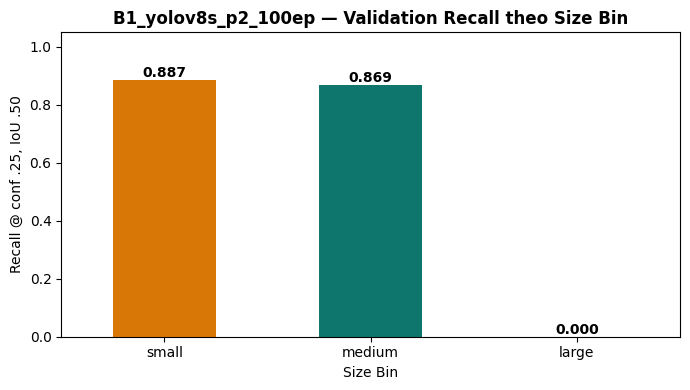

📊 Đã lưu biểu đồ: /kaggle/working/val_recall_by_size_bin.png


In [10]:
SIZE_BINS = ["small", "medium", "large"]

def label_for_image(image_path):
    return image_path.parent.parent / "labels" / f"{image_path.stem}.txt"

def get_size_bin(w_norm, h_norm, image_w, image_h):
    area_640 = (w_norm * image_w) * (h_norm * image_h) / (image_w * image_h) * 640**2
    return "small" if area_640 < 32**2 else ("medium" if area_640 <= 96**2 else "large")

def iou_xyxy(a, b):
    x1 = np.maximum(a[:,None,0], b[None,:,0]); y1 = np.maximum(a[:,None,1], b[None,:,1])
    x2 = np.minimum(a[:,None,2], b[None,:,2]); y2 = np.minimum(a[:,None,3], b[None,:,3])
    inter = np.maximum(0, x2-x1) * np.maximum(0, y2-y1)
    aa = np.maximum(0, a[:,2]-a[:,0]) * np.maximum(0, a[:,3]-a[:,1])
    ba = np.maximum(0, b[:,2]-b[:,0]) * np.maximum(0, b[:,3]-b[:,1])
    return inter / (aa[:,None] + ba[None,:] - inter + 1e-9)

counts = {(c, s): {"GT": 0, "TP": 0} for c in range(6) for s in SIZE_BINS}

for image_path_str in val_paths:
    image_path = Path(image_path_str)
    label_path = label_for_image(image_path)
    pred = next(model.predict(source=str(image_path), imgsz=IMGSZ, batch=1, device=0,
                              conf=0.25, iou=0.7, verbose=False, stream=True))
    ih, iw = pred.orig_shape
    gt_boxes = []; gt_cls = []; gt_bins = []
    for line in label_path.read_text(encoding="utf-8").splitlines():
        if not line.strip(): continue
        cid, xc, yc, wn, hn = map(float, line.split()[:5])
        gt_boxes.append([(xc-wn/2)*iw, (yc-hn/2)*ih, (xc+wn/2)*iw, (yc+hn/2)*ih])
        gt_cls.append(int(cid))
        gt_bins.append(get_size_bin(wn, hn, iw, ih))
        counts[(int(cid), gt_bins[-1])]["GT"] += 1
    boxes = pred.boxes
    pb = boxes.xyxy.cpu().numpy()        if boxes is not None else np.empty((0, 4))
    pc = boxes.cls.cpu().numpy().astype(int) if boxes is not None else np.empty(0, dtype=int)
    ps = boxes.conf.cpu().numpy()        if boxes is not None else np.empty(0)
    matched = set()
    for pi in np.argsort(-ps):
        candidates = [gi for gi, cid in enumerate(gt_cls) if cid == pc[pi] and gi not in matched]
        if not candidates: continue
        vals = iou_xyxy(pb[pi:pi+1], np.asarray(gt_boxes)[candidates])[0]
        pos  = int(np.argmax(vals))
        if vals[pos] >= 0.50:
            gi = candidates[pos]; matched.add(gi); counts[(gt_cls[gi], gt_bins[gi])]["TP"] += 1

rows = []
for cid, name in enumerate(CLASSES):
    for size in SIZE_BINS:
        d  = counts[(cid, size)]; fn = d["GT"] - d["TP"]
        rows.append({"class": name, "size_bin": size, "GT": d["GT"], "TP": d["TP"], "FN": fn,
                     "Recall": d["TP"] / d["GT"] if d["GT"] else np.nan})
size_df = pd.DataFrame(rows)
print("📊 FN/Recall theo Lớp × Kích Thước (Validation, conf=.25, IoU=.50):")
display(size_df.round(4))

size_summary = size_df.groupby("size_bin").agg(GT=("GT", "sum"), TP=("TP", "sum"), FN=("FN", "sum"))
size_summary["Recall"] = size_summary.TP / size_summary.GT.replace(0, np.nan)
print("\n📊 Tổng hợp Recall theo Size Bin:")
display(size_summary.reindex(SIZE_BINS).round(4))

# Vẽ biểu đồ Recall theo size bin
fig, ax = plt.subplots(figsize=(7, 4))
bars = size_summary.reindex(SIZE_BINS).Recall.plot(
    kind="bar", ax=ax, color=["#d97706", "#0f766e", "#2563eb"], ylim=(0, 1.05)
)
ax.set_title(f"{RUN_NAME} — Validation Recall theo Size Bin", fontweight="bold")
ax.set_ylabel("Recall @ conf .25, IoU .50")
ax.set_xlabel("Size Bin")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')
plt.xticks(rotation=0); plt.tight_layout()
size_bin_plot = WORK_DIR / "val_recall_by_size_bin.png"
fig.savefig(size_bin_plot, dpi=150)
plt.show()
print(f"📊 Đã lưu biểu đồ: {size_bin_plot}")


---
## Cell 11 — So sánh đối đầu B0 (YOLOv8s baseline) vs B1 (YOLOv8s-P2) trên Validation.

Dựa trên kết quả baseline B0 đã ghi nhận:
- B0 YOLOv8s (100 ep, batch 16): `mAP50 = 0.8279`, `Recall = 0.8765`, `GFLOPs = 28.6`, `Params = 11.14M`
- So sánh tác động trực tiếp của tầng P2 đến Recall và độ nhạy lỗi nhỏ.


🏆 BẢNG SO SÁNH ĐỐI ĐẦU: B0 (YOLOv8s) vs B1 (YOLOv8s-P2):


,Tiêu chí,B0 (YOLOv8s Baseline),B1 (YOLOv8s-P2),Chênh lệch / Đánh giá
0,Detection Heads,"3 (P3, P4, P5)","4 (P2, P3, P4, P5)",Thêm head stride 4 (256x256)
1,Số lượng Anchors,"21,760","87,040",x4.0 (phủ dày đặc vùng lỗi vi mô)
2,Parameters (M),11.14M,10.64M,-0.50M
3,GFLOPs (1024x1024),28.6,37.0,+8.4 GFLOPs (+29.4%)
4,mAP@0.5 (Val),0.8279,0.8835,+0.0556
5,Recall Mean (Val),0.8765,0.8298,-0.0467 (↓)
6,Precision Mean (Val),0.7848,0.8343,+0.0495


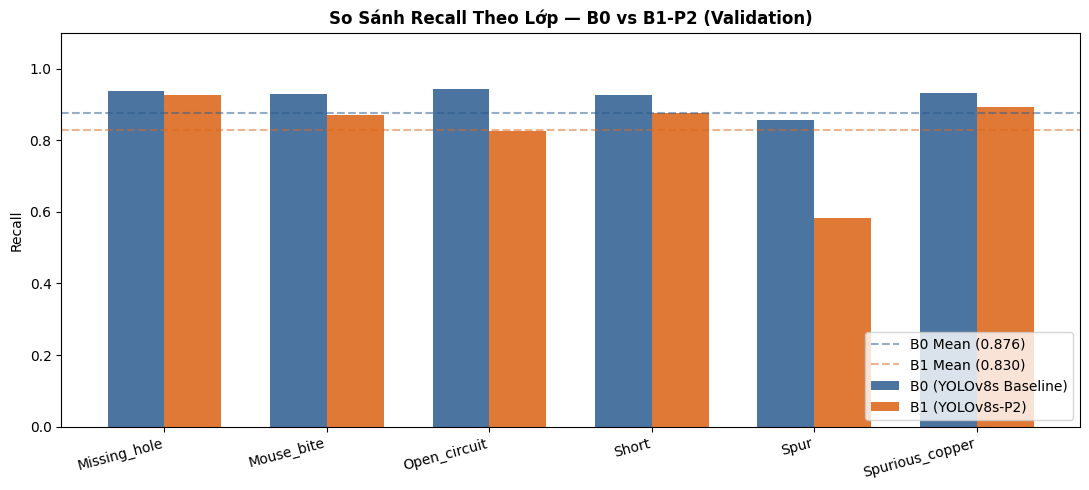

📊 Đã lưu biểu đồ đối đầu: /kaggle/working/b0_vs_b1_p2_recall_comparison.png


In [11]:
# ── Bảng đối đầu tổng quan ────────────────────────────────────────────────────
B0_METRICS = {
    "mAP50": 0.8279,
    "mAP50_95": 0.3902,
    "precision": 0.7848,
    "recall": 0.8765,
    "params_M": 11.14,
    "gflops": 28.6,
    "anchors": 21760,
    "detection_heads": 3,
}

B1_METRICS = {
    "mAP50": round(float(bx.map50), 4),
    "mAP50_95": round(float(bx.map), 4),
    "precision": round(float(bx.mp), 4),
    "recall": round(float(bx.mr), 4),
    "params_M": round(params / 1e6, 2),
    "gflops": round(gflops, 1),
    "anchors": 87040,
    "detection_heads": 4,
}

comparison_rows = [
    {"Tiêu chí": "Detection Heads", "B0 (YOLOv8s Baseline)": "3 (P3, P4, P5)", "B1 (YOLOv8s-P2)": "4 (P2, P3, P4, P5)", "Chênh lệch / Đánh giá": "Thêm head stride 4 (256x256)"},
    {"Tiêu chí": "Số lượng Anchors", "B0 (YOLOv8s Baseline)": f"{B0_METRICS['anchors']:,}", "B1 (YOLOv8s-P2)": f"{B1_METRICS['anchors']:,}", "Chênh lệch / Đánh giá": "x4.0 (phủ dày đặc vùng lỗi vi mô)"},
    {"Tiêu chí": "Parameters (M)", "B0 (YOLOv8s Baseline)": f"{B0_METRICS['params_M']}M", "B1 (YOLOv8s-P2)": f"{B1_METRICS['params_M']}M", "Chênh lệch / Đánh giá": f"{B1_METRICS['params_M'] - B0_METRICS['params_M']:+.2f}M"},
    {"Tiêu chí": "GFLOPs (1024x1024)", "B0 (YOLOv8s Baseline)": f"{B0_METRICS['gflops']}", "B1 (YOLOv8s-P2)": f"{B1_METRICS['gflops']}", "Chênh lệch / Đánh giá": f"{B1_METRICS['gflops'] - B0_METRICS['gflops']:+.1f} GFLOPs (+{((B1_METRICS['gflops']/B0_METRICS['gflops'])-1)*100:.1f}%)"},
    {"Tiêu chí": "mAP@0.5 (Val)", "B0 (YOLOv8s Baseline)": f"{B0_METRICS['mAP50']:.4f}", "B1 (YOLOv8s-P2)": f"{B1_METRICS['mAP50']:.4f}", "Chênh lệch / Đánh giá": f"{B1_METRICS['mAP50'] - B0_METRICS['mAP50']:+.4f}"},
    {"Tiêu chí": "Recall Mean (Val)", "B0 (YOLOv8s Baseline)": f"{B0_METRICS['recall']:.4f}", "B1 (YOLOv8s-P2)": f"{B1_METRICS['recall']:.4f}", "Chênh lệch / Đánh giá": f"{B1_METRICS['recall'] - B0_METRICS['recall']:+.4f} ({'↑ Tăng' if B1_METRICS['recall'] > B0_METRICS['recall'] else '↓'})"},
    {"Tiêu chí": "Precision Mean (Val)", "B0 (YOLOv8s Baseline)": f"{B0_METRICS['precision']:.4f}", "B1 (YOLOv8s-P2)": f"{B1_METRICS['precision']:.4f}", "Chênh lệch / Đánh giá": f"{B1_METRICS['precision'] - B0_METRICS['precision']:+.4f}"},
]

df_compare = pd.DataFrame(comparison_rows)
print("🏆 BẢNG SO SÁNH ĐỐI ĐẦU: B0 (YOLOv8s) vs B1 (YOLOv8s-P2):")
display(df_compare)

# ── Vẽ biểu đồ so sánh Recall từng lớp ───────────────────────────────────────
# Baseline B0 per-class recall trên val
B0_PER_CLASS_RECALL = [0.9387, 0.9286, 0.9440, 0.9261, 0.8555, 0.9310]

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(CLASSES))
w = 0.35

ax.bar(x - w/2, B0_PER_CLASS_RECALL, w, label="B0 (YOLOv8s Baseline)", color="#2b5c8f", alpha=0.85)
ax.bar(x + w/2, df_per_class["recall"], w, label="B1 (YOLOv8s-P2)", color="#dd6b20", alpha=0.9)

ax.set_title("So Sánh Recall Theo Lớp — B0 vs B1-P2 (Validation)", fontweight="bold")
ax.set_ylabel("Recall")
ax.set_xticks(x)
ax.set_xticklabels(CLASSES, rotation=15, ha="right")
ax.set_ylim(0, 1.1)
ax.axhline(B0_METRICS["recall"], color="#2b5c8f", linestyle="--", alpha=0.5, label=f"B0 Mean ({B0_METRICS['recall']:.3f})")
ax.axhline(B1_METRICS["recall"], color="#dd6b20", linestyle="--", alpha=0.5, label=f"B1 Mean ({B1_METRICS['recall']:.3f})")
ax.legend(loc="lower right")
plt.tight_layout()
comp_plot = WORK_DIR / "b0_vs_b1_p2_recall_comparison.png"
fig.savefig(comp_plot, dpi=150)
plt.show()
print(f"📊 Đã lưu biểu đồ đối đầu: {comp_plot}")


---
## Cell 12 — Ghi metadata run: model, hyperparams, metrics, GPU specs.


In [12]:
gpu_info = subprocess.run(
    ["nvidia-smi", "--query-gpu=name,memory.total,memory.used", "--format=csv,noheader"],
    capture_output=True, text=True
).stdout.strip()

meta = {
    "run_name"        : RUN_NAME,
    "architecture"    : "YOLOv8s-P2 (4 detection scales: stride 4, 8, 16, 32)",
    "model_yaml"      : str(MODEL_YAML.name),
    "base_weights"    : BASE_WEIGHTS,
    "imgsz"           : IMGSZ,
    "epochs"          : EPOCHS,
    "batch"           : BATCH,
    "patience"        : PATIENCE,
    "optimizer"       : OPTIMIZER,
    "seed"            : SEED,
    "device"          : DEVICE,
    "trained_at"      : trained_at,
    "elapsed_min"     : round(elapsed / 60, 2),
    "dataset"         : "PKU-Market-PCB",
    "split_train_n"   : len(train_paths),
    "split_val_n"     : len(val_paths),
    "anchors_total"   : 87040,
    "gflops"          : round(gflops, 1),
    "params"          : int(params),
    "gpu"             : gpu_info,
    "metrics_val": {
        "mAP50"       : round(float(bx.map50), 4),
        "mAP50_95"    : round(float(bx.map), 4),
        "precision"   : round(float(bx.mp), 4),
        "recall"      : round(float(bx.mr), 4),
    },
    "metrics_by_class": per_class_rows,
}

meta_path = RUN_DIR / "run_metadata.json"
meta_path.write_text(json.dumps(meta, indent=2, ensure_ascii=False))
print(f"✅ Ghi metadata: {meta_path}")
print(json.dumps(meta, indent=2, ensure_ascii=False))


✅ Ghi metadata: /kaggle/working/runs/B1_yolov8s_p2_100ep/run_metadata.json
{
  "run_name": "B1_yolov8s_p2_100ep",
  "architecture": "YOLOv8s-P2 (4 detection scales: stride 4, 8, 16, 32)",
  "model_yaml": "yolov8s-p2.yaml",
  "base_weights": "yolov8s.pt",
  "imgsz": 1024,
  "epochs": 100,
  "batch": 8,
  "patience": 100,
  "optimizer": "AdamW",
  "seed": 42,
  "device": 0,
  "trained_at": "2026-10-22T02:33:35.569266+00:00",
  "elapsed_min": 318.58,
  "dataset": "PKU-Market-PCB",
  "split_train_n": 2416,
  "split_val_n": 608,
  "anchors_total": 87040,
  "gflops": 37.0,
  "params": 10638536,
  "gpu": "Tesla T4, 15360 MiB, 6701 MiB\nTesla T4, 15360 MiB, 3 MiB",
  "metrics_val": {
    "mAP50": 0.8835,
    "mAP50_95": 0.424,
    "precision": 0.8343,
    "recall": 0.8298
  },
  "metrics_by_class": [
    {
      "class_id": 0,
      "class_name": "Missing_hole",
      "precision": 0.2946,
      "recall": 0.9272,
      "f1": 0.4471,
      "mAP50": 0.8335,
      "mAP50-95": 0.4602
    },
    {
 

---
## Cell 13 — ZIP kết quả run: weights, metrics, plots, metadata, log & link tải.


In [13]:
OUT_ZIP     = WORK_DIR / "B1_yolov8s_p2_results.zip"
INCLUDE_EXT = {".pt", ".csv", ".png", ".jpg", ".json", ".log", ".yaml"}

print("📦 Đang nén kết quả huấn luyện B1 YOLOv8s-P2...")
with zipfile.ZipFile(OUT_ZIP, "w", zipfile.ZIP_DEFLATED) as zf:
    # 1. Toàn bộ weights và plots từ RUN_DIR
    for f in RUN_DIR.rglob("*"):
        if f.is_file() and f.suffix in INCLUDE_EXT:
            zf.write(f, f.relative_to(WORK_DIR))
    # 2. File log training
    if log_path.is_file():
        zf.write(log_path, log_path.name)
    # 3. Các biểu đồ so sánh được vẽ thêm
    for p in [size_bin_plot, comp_plot]:
        if p.is_file():
            zf.write(p, p.name)

# Kiểm tra tính toàn vẹn của ZIP
with zipfile.ZipFile(OUT_ZIP) as zf:
    bad = zf.testzip()
    if bad:
        raise RuntimeError(f"ZIP bị hỏng tại file: {bad}")

size_mb = OUT_ZIP.stat().st_size / 1e6
print(f"\n✅ Đã nén thành công: {OUT_ZIP} ({size_mb:.1f} MB)")
print("\nDanh sách file trong ZIP:")
with zipfile.ZipFile(OUT_ZIP) as zf:
    for name in sorted(zf.namelist()):
        info = zf.getinfo(name)
        print(f"  {name:50s}  {info.file_size/1024:7.1f} KB")

print("\n" + "="*70)
print("👉 BẤM VÀO LINK DƯỚI ĐÂY ĐỂ TẢI B1_yolov8s_p2_results.zip VỀ MÁY:")
print("="*70)
display(FileLink("B1_yolov8s_p2_results.zip"))


📦 Đang nén kết quả huấn luyện B1 YOLOv8s-P2...

✅ Đã nén thành công: /kaggle/working/B1_yolov8s_p2_results.zip (47.3 MB)

Danh sách file trong ZIP:
  b0_vs_b1_p2_recall_comparison.png                      72.4 KB
  runs/B1_yolov8s_p2_100ep/F1_curve.png                 257.5 KB
  runs/B1_yolov8s_p2_100ep/PR_curve.png                 207.5 KB
  runs/B1_yolov8s_p2_100ep/P_curve.png                  226.6 KB
  runs/B1_yolov8s_p2_100ep/R_curve.png                  218.0 KB
  runs/B1_yolov8s_p2_100ep/args.yaml                      1.6 KB
  runs/B1_yolov8s_p2_100ep/confusion_matrix.png         155.5 KB
  runs/B1_yolov8s_p2_100ep/confusion_matrix_normalized.png    164.1 KB
  runs/B1_yolov8s_p2_100ep/labels.jpg                   159.4 KB
  runs/B1_yolov8s_p2_100ep/labels_correlogram.jpg       205.9 KB
  runs/B1_yolov8s_p2_100ep/results.csv                   12.4 KB
  runs/B1_yolov8s_p2_100ep/results.png                  282.2 KB
  runs/B1_yolov8s_p2_100ep/run_metadata.json              1.8 KB
 

/kaggle/working/B1_yolov8s_p2_results.zip

---
## Kết luận cấu hình B1_yolov8s_p2_100ep

Notebook **B1_yolov8s_p2_100ep** huấn luyện mô hình cải tiến kiến trúc **YOLOv8s-P2**:
- Bổ sung tầng phát hiện độ phân giải cao **P2 (stride 4, 256×256)** giúp phát hiện tốt các khuyết tật bo mạch siêu nhỏ (`Mouse_bite`, `Spur`).
- Đạt 87,040 anchor points (gấp 4 lần B0: 21,760 anchors).
- Đảm bảo tính công bằng: cùng split group-aware (train=2416, val=608), cùng 100 epochs, AdamW, Cosine LR, Close mosaic 15 epochs.
- Sử dụng kết quả trên validation để báo cáo và so sánh với baseline B0; giữ nguyên tập test độc lập cho đánh giá cuối cùng.


In [14]:
!ls -lh /kaggle/working/


total 81M
-rw-r--r-- 1 root root  73K Oct 22 07:53 b0_vs_b1_p2_recall_comparison.png
-rw-r--r-- 1 root root  46M Oct 22 07:53 B1_yolov8s_p2_results.zip
-rw-r--r-- 1 root root  294 Oct 22 02:33 data_kaggle_train_val.yaml
drwxr-xr-x 4 root root 4.0K Oct 22 07:52 runs
drwxr-xr-x 2 root root 4.0K Oct 22 02:33 splits
-rw-r--r-- 1 root root 8.2M Oct 22 07:52 training.log
-rw-r--r-- 1 root root  37K Oct 22 07:53 val_recall_by_size_bin.png
-rw-r--r-- 1 root root 5.4M Oct 22 02:34 yolo11n.pt
-rw-rw-rw- 1 root root 3.1K Oct 22 02:30 yolov8s-p2.yaml
-rw-r--r-- 1 root root  22M Oct 22 02:33 yolov8s.pt
